=== Library Versions ===
Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3 | Sklearn: 1.6.1 | Seed: 42

Dataset Shape: 569 rows x 31 columns (30 numerical features + 1 binary target)

First 5 Records:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1



Data Types Summary:
float64    30
int64       1
Name: count, dtype: int64

Missing Values     : 0
Duplicate Rows     : 0
Unique Target Vals : [0, 1] (consistent binary labels)

Summary Statistics (First 10 Mean Features):


,count,mean,std,min,50%,max
mean radius,569.0,14.127,3.524,6.981,13.370,28.110
mean texture,569.0,19.290,4.301,9.710,18.840,39.280
mean perimeter,569.0,91.969,24.299,43.790,86.240,188.500
mean area,569.0,654.889,351.914,143.500,551.100,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.096,0.163
mean compactness,569.0,0.104,0.053,0.019,0.093,0.345
mean concavity,569.0,0.089,0.080,0.000,0.062,0.427
mean concave points,569.0,0.049,0.039,0.000,0.034,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.179,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.062,0.097



Class Distribution:


,Class,Count,Percentage (%)
0,0 = Benign (Negative),357,62.74
1,1 = Malignant (Positive),212,37.26


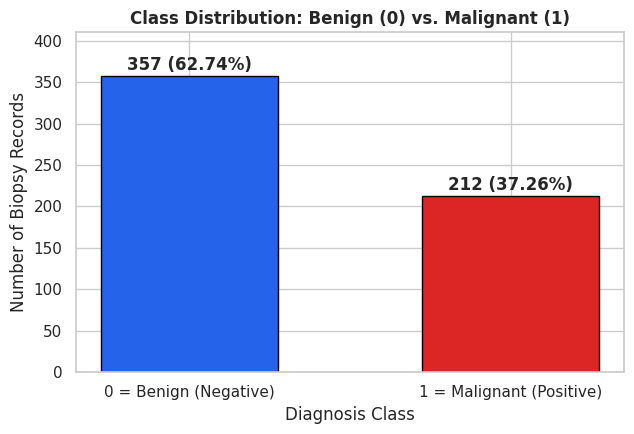

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, precision_recall_curve,
    average_precision_score, classification_report
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")

print("=== Library Versions ===")
print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__} | Sklearn: {sklearn.__version__} | Seed: {RANDOM_STATE}")

# Load dataset and re-encode target so 1 = Malignant (Positive), 0 = Benign (Negative)
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()
df['diagnosis'] = (df['target'] == 0).astype(int)
df = df.drop(columns=['target'])

# Save CSV copy for GitHub repository
df.to_csv("breast_cancer_dataset.csv", index=False)

print(f"\nDataset Shape: {df.shape[0]} rows x {df.shape[1]} columns (30 numerical features + 1 binary target)")
print("\nFirst 5 Records:")
display(df.head())

print("\nData Types Summary:")
print(df.dtypes.value_counts())

print(f"\nMissing Values     : {df.isnull().sum().sum()}")
print(f"Duplicate Rows     : {df.duplicated().sum()}")
print(f"Unique Target Vals : {sorted(df['diagnosis'].unique().tolist())} (consistent binary labels)")

print("\nSummary Statistics (First 10 Mean Features):")
display(df.iloc[:, :10].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(3))

# Class counts & bar chart
class_counts = df['diagnosis'].value_counts().sort_index()
class_pct = (df['diagnosis'].value_counts(normalize=True).sort_index() * 100).round(2)
dist_df = pd.DataFrame({'Class': ['0 = Benign (Negative)', '1 = Malignant (Positive)'], 'Count': class_counts.values, 'Percentage (%)': class_pct.values})
print("\nClass Distribution:")
display(dist_df)

plt.figure(figsize=(6.5, 4.5))
bars = plt.bar(dist_df['Class'], dist_df['Count'], color=['#2563eb', '#dc2626'], edgecolor='black', width=0.55)
plt.title("Class Distribution: Benign (0) vs. Malignant (1)", fontsize=12, fontweight='bold')
plt.xlabel("Diagnosis Class")
plt.ylabel("Number of Biopsy Records")
plt.ylim(0, 410)
for bar, cnt, pct in zip(bars, dist_df['Count'], dist_df['Percentage (%)']):
    plt.text(bar.get_x() + bar.get_width()/2, cnt + 8, f"{cnt} ({pct}%)", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

=== Stratified Split Summary ===


,Dataset,Total Rows,Benign (0),Malignant (1),Malignant Share (%)
0,Training Set (80%),455,285,170,37.36
1,Testing Set (20%),114,72,42,36.84


StandardScaler fitted on X_train only -> Train scaled mean (approx 0): 0.0 | Std (approx 1): 1.0


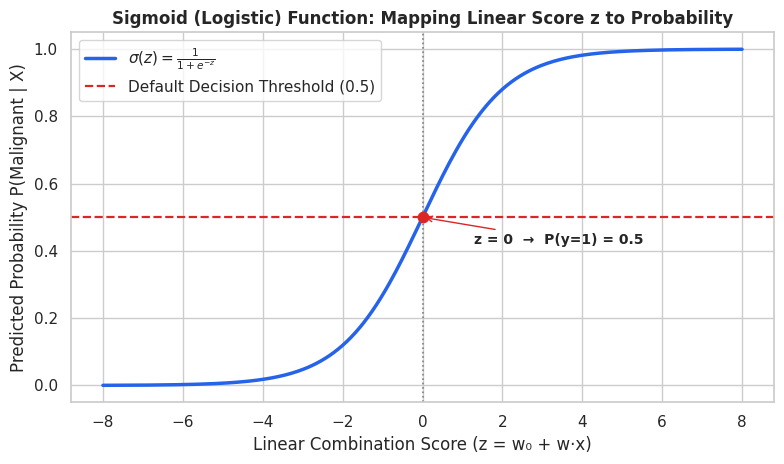

In [2]:
# Separate features (X) and binary target (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

# Step 4: Stratified 80:20 Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Record sizes and class proportions in both sets
split_summary = pd.DataFrame({
    'Dataset': ['Training Set (80%)', 'Testing Set (20%)'],
    'Total Rows': [len(X_train), len(X_test)],
    'Benign (0)': [(y_train == 0).sum(), (y_test == 0).sum()],
    'Malignant (1)': [(y_train == 1).sum(), (y_test == 1).sum()],
    'Malignant Share (%)': [round(y_train.mean()*100, 2), round(y_test.mean()*100, 2)]
})
print("=== Stratified Split Summary ===")
display(split_summary)

# Fit StandardScaler on TRAINING DATA ONLY, then transform both train and test
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)
print("StandardScaler fitted on X_train only -> Train scaled mean (approx 0):", round(X_train_sc.mean(), 4), "| Std (approx 1):", round(X_train_sc.std(), 4))

# Step 5: Plot the Sigmoid Curve
z = np.linspace(-8, 8, 300)
sigmoid = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 4.8))
plt.plot(z, sigmoid, color='#2563eb', linewidth=2.5, label=r'$\sigma(z) = \frac{1}{1 + e^{-z}}$')
plt.axhline(0.5, color='#dc2626', linestyle='--', linewidth=1.6, label='Default Decision Threshold (0.5)')
plt.axvline(0.0, color='gray', linestyle=':', linewidth=1.2)
plt.scatter([0], [0.5], color='#dc2626', zorder=5, s=55)
plt.annotate('z = 0  →  P(y=1) = 0.5', xy=(0, 0.5), xytext=(1.3, 0.42),
             arrowprops=dict(arrowstyle='->', color='#dc2626'), fontsize=10, fontweight='bold')
plt.title("Sigmoid (Logistic) Function: Mapping Linear Score z to Probability", fontsize=12, fontweight='bold')
plt.xlabel("Linear Combination Score (z = w₀ + w·x)")
plt.ylabel("Predicted Probability P(Malignant | X)")
plt.ylim(-0.05, 1.05)
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

=== Model Settings ===
Solver: lbfgs | Penalty: l2 | C: 1.0 | max_iter: 1000 | random_state: 42

Learned Intercept (w0): -0.2430

=== All 30 Learned Coefficients (Sorted High to Low) ===


,Feature,Coefficient (Log-Odds per +1 SD)
0,worst texture,1.4341
1,radius error,1.2333
2,worst symmetry,1.0613
3,mean concave points,0.9528
4,worst concavity,0.9114
5,area error,0.9090
6,worst area,0.9005
7,worst radius,0.8970
8,mean concavity,0.7823
9,perimeter error,0.7483


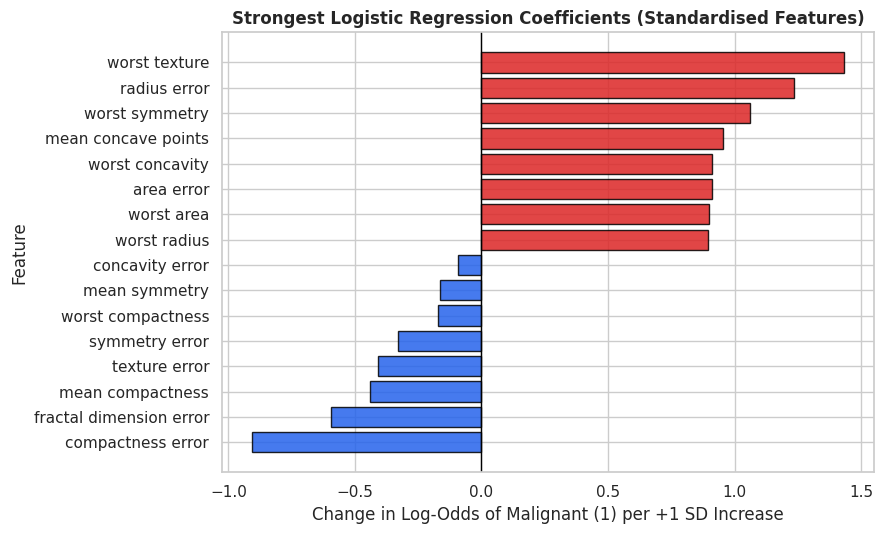


=== Sample of 12 Unseen Test Records (Actual vs. Probability vs. Labels) ===


,Actual_Label,Pred_Prob_Malignant,Pred_at_0.3,Pred_at_0.5,Pred_at_0.7
120,0,0.0004,0,0,0
250,1,1.0000,1,1,1
375,0,0.0426,0,0,0
99,1,0.5762,1,1,0
455,0,0.5092,1,1,0
318,0,0.0006,0,0,0
39,1,0.7615,1,1,1
371,0,0.0010,0,0,0
98,0,0.0006,0,0,0
502,0,0.0108,0,0,0



=== Effect of Decision Threshold on Predicted Positive Count (Test Set, n = 114) ===


,Threshold,Predicted_Malignant (1),Predicted_Benign (0),Actual_Malignant_in_Test
0,0.3,42,72,42
1,0.5,40,74,42
2,0.7,38,76,42


In [3]:
# Step 6: Train Logistic Regression on scaled training data ONLY
clf = LogisticRegression(solver='lbfgs', C=1.0, max_iter=1000, random_state=RANDOM_STATE)
clf.fit(X_train_sc, y_train)

print("=== Model Settings ===")
print(f"Solver: {clf.solver} | Penalty: {clf.penalty} | C: {clf.C} | max_iter: {clf.max_iter} | random_state: {clf.random_state}")
print(f"\nLearned Intercept (w0): {clf.intercept_[0]:.4f}")

# Record all 30 learned coefficients with feature names
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (Log-Odds per +1 SD)': clf.coef_[0]
}).sort_values('Coefficient (Log-Odds per +1 SD)', ascending=False).reset_index(drop=True)

print("\n=== All 30 Learned Coefficients (Sorted High to Low) ===")
display(coef_df.round(4))

# Plot top 8 positive & top 8 negative coefficients for readability
top_bot = pd.concat([coef_df.head(8), coef_df.tail(8)]).sort_values('Coefficient (Log-Odds per +1 SD)')
plt.figure(figsize=(9, 5.5))
colors = ['#dc2626' if v > 0 else '#2563eb' for v in top_bot['Coefficient (Log-Odds per +1 SD)']]
plt.barh(top_bot['Feature'], top_bot['Coefficient (Log-Odds per +1 SD)'], color=colors, edgecolor='black', alpha=0.85)
plt.axvline(0, color='black', linewidth=1.0)
plt.title("Strongest Logistic Regression Coefficients (Standardised Features)", fontsize=12, fontweight='bold')
plt.xlabel("Change in Log-Odds of Malignant (1) per +1 SD Increase")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Step 7: Obtain predicted probabilities & labels on unseen test set
y_test_prob = clf.predict_proba(X_test_sc)[:, 1]
y_test_pred = clf.predict(X_test_sc)  # uses default 0.5 threshold

# Sample of 12 test records showing actual label, predicted probability & predicted label
sample_preds = pd.DataFrame({
    'Actual_Label': y_test.values,
    'Pred_Prob_Malignant': y_test_prob,
    'Pred_at_0.3': (y_test_prob >= 0.3).astype(int),
    'Pred_at_0.5': y_test_pred,
    'Pred_at_0.7': (y_test_prob >= 0.7).astype(int)
}, index=y_test.index)

print("\n=== Sample of 12 Unseen Test Records (Actual vs. Probability vs. Labels) ===")
display(sample_preds.head(12).round(4))

# Effect of changing threshold (0.3, 0.5, 0.7) on count of records predicted positive
thresh_counts = pd.DataFrame([
    {'Threshold': th,
     'Predicted_Malignant (1)': int((y_test_prob >= th).sum()),
     'Predicted_Benign (0)': int((y_test_prob < th).sum()),
     'Actual_Malignant_in_Test': int(y_test.sum())}
    for th in [0.3, 0.5, 0.7]
])
print("\n=== Effect of Decision Threshold on Predicted Positive Count (Test Set, n = 114) ===")
display(thresh_counts)

=== Confusion Matrix Breakdown (Test Set, n = 114, Threshold = 0.5) ===
TP (True Malignant caught)  : 39
FP (Benign false alarm)     : 1
FN (Missed Malignant cancer): 3
TN (Benign cleared)         : 71

=== Classification Report (Test Set, Threshold = 0.5) ===
               precision    recall  f1-score   support

   Benign (0)       0.96      0.99      0.97        72
Malignant (1)       0.97      0.93      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.96      0.96       114
 weighted avg       0.97      0.96      0.96       114

=== Baseline vs. Logistic Regression Comparison ===


,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score
0,Majority-Class Baseline (Always Benign),0.6316,0.000,0.0000,1.0000,0.0000
1,Logistic Regression (Threshold = 0.5),0.9649,0.975,0.9286,0.9861,0.9512



=== Training vs. Testing Performance (Overfitting / Underfitting Check) ===


,Split,Accuracy,Precision,Recall,Specificity,F1-Score,ROC-AUC
0,Training Set (n = 455),0.9868,1.000,0.9647,1.0000,0.9820,0.9976
1,Testing Set (n = 114),0.9649,0.975,0.9286,0.9861,0.9512,0.9960



=== Threshold Comparison Table (Test Set) ===


,Threshold,Predicted Positive,TP,FP,FN,TN,Accuracy,Precision,Recall,Specificity,F1-Score
0,0.3,42,41,1,1,71,0.9825,0.9762,0.9762,0.9861,0.9762
1,0.5,40,39,1,3,71,0.9649,0.9750,0.9286,0.9861,0.9512
2,0.7,38,38,0,4,72,0.9649,1.0000,0.9048,1.0000,0.9500


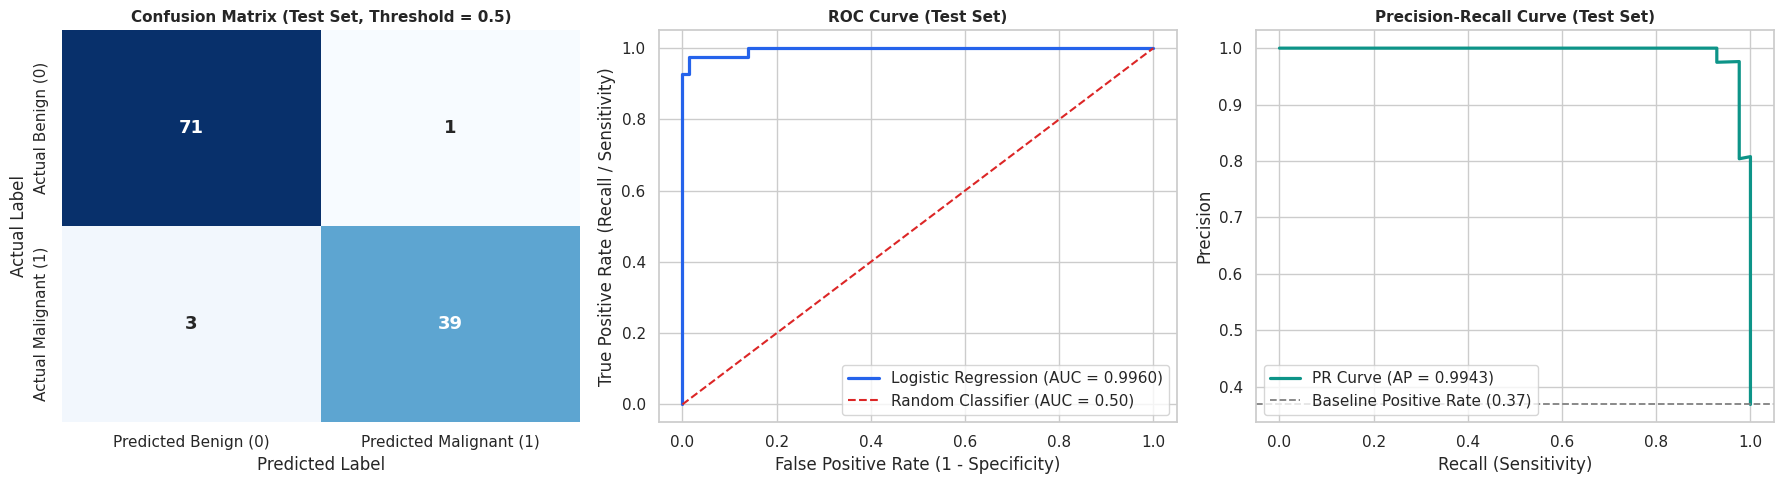

In [5]:
# --- 1. Confusion Matrix (Test Set, Default Threshold = 0.5) ---
cm = confusion_matrix(y_test, y_test_pred)
tn, fp, fn, tp = cm.ravel()

acc = (tp + tn) / (tp + tn + fp + fn)
prec = tp / (tp + fp)
rec = tp / (tp + fn)
spec = tn / (tn + fp)
f1 = 2 * (prec * rec) / (prec + rec)
roc_auc = roc_auc_score(y_test, y_test_prob)
pr_auc = average_precision_score(y_test, y_test_prob)

print(f"=== Confusion Matrix Breakdown (Test Set, n = {len(y_test)}, Threshold = 0.5) ===")
print(f"TP (True Malignant caught)  : {tp}")
print(f"FP (Benign false alarm)     : {fp}")
print(f"FN (Missed Malignant cancer): {fn}")
print(f"TN (Benign cleared)         : {tn}")

# --- 2. Full Classification Report ---
print("\n=== Classification Report (Test Set, Threshold = 0.5) ===")
print(classification_report(y_test, y_test_pred, target_names=['Benign (0)', 'Malignant (1)']))

# --- 3. Majority-Class Baseline vs. Logistic Regression (Test Set) ---
y_base_pred = np.zeros_like(y_test)  # Always predict Benign (0)
base_df = pd.DataFrame([
    {'Model': 'Majority-Class Baseline (Always Benign)',
     'Accuracy': accuracy_score(y_test, y_base_pred),
     'Precision': 0.0,
     'Recall (Sensitivity)': recall_score(y_test, y_base_pred),
     'Specificity': 1.0,
     'F1-Score': f1_score(y_test, y_base_pred)},
    {'Model': 'Logistic Regression (Threshold = 0.5)',
     'Accuracy': acc, 'Precision': prec, 'Recall (Sensitivity)': rec,
     'Specificity': spec, 'F1-Score': f1}
])
print("=== Baseline vs. Logistic Regression Comparison ===")
display(base_df.round(4))

# --- 4. Train vs. Test Overfitting Check (Threshold = 0.5) ---
y_train_prob = clf.predict_proba(X_train_sc)[:, 1]
y_train_pred = clf.predict(X_train_sc)
tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_train, y_train_pred).ravel()

overfit_df = pd.DataFrame([
    {'Split': 'Training Set (n = 455)',
     'Accuracy': accuracy_score(y_train, y_train_pred),
     'Precision': precision_score(y_train, y_train_pred),
     'Recall': recall_score(y_train, y_train_pred),
     'Specificity': tn_tr / (tn_tr + fp_tr),
     'F1-Score': f1_score(y_train, y_train_pred),
     'ROC-AUC': roc_auc_score(y_train, y_train_prob)},
    {'Split': 'Testing Set (n = 114)',
     'Accuracy': acc, 'Precision': prec, 'Recall': rec,
     'Specificity': spec, 'F1-Score': f1, 'ROC-AUC': roc_auc}
])
print("\n=== Training vs. Testing Performance (Overfitting / Underfitting Check) ===")
display(overfit_df.round(4))

# --- 5. Threshold Comparison Table (0.3, 0.5, 0.7) ---
rows = []
for th in [0.3, 0.5, 0.7]:
    yp = (y_test_prob >= th).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, yp).ravel()
    rows.append({
        'Threshold': th,
        'Predicted Positive': int(yp.sum()),
        'TP': int(tp_t), 'FP': int(fp_t), 'FN': int(fn_t), 'TN': int(tn_t),
        'Accuracy': accuracy_score(y_test, yp),
        'Precision': precision_score(y_test, yp),
        'Recall': recall_score(y_test, yp),
        'Specificity': tn_t / (tn_t + fp_t),
        'F1-Score': f1_score(y_test, yp)
    })
thresh_table = pd.DataFrame(rows)
print("\n=== Threshold Comparison Table (Test Set) ===")
display(thresh_table.round(4))

# --- 6. Plot Confusion Matrix, ROC Curve, and Precision-Recall Curve ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Confusion Matrix Heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Predicted Benign (0)', 'Predicted Malignant (1)'],
            yticklabels=['Actual Benign (0)', 'Actual Malignant (1)'],
            annot_kws={'size': 13, 'weight': 'bold'})
axes[0].set_title("Confusion Matrix (Test Set, Threshold = 0.5)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

# Plot 2: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_test_prob)
axes[1].plot(fpr, tpr, color='#2563eb', linewidth=2.3, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='#dc2626', linestyle='--', linewidth=1.5, label='Random Classifier (AUC = 0.50)')
axes[1].set_title("ROC Curve (Test Set)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Recall / Sensitivity)")
axes[1].legend(loc='lower right')

# Plot 3: Precision-Recall Curve
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_test_prob)
axes[2].plot(rec_curve, prec_curve, color='#0d9488', linewidth=2.3, label=f'PR Curve (AP = {pr_auc:.4f})')
axes[2].axhline(y_test.mean(), color='gray', linestyle='--', linewidth=1.3, label=f'Baseline Positive Rate ({y_test.mean():.2f})')
axes[2].set_title("Precision-Recall Curve (Test Set)", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Recall (Sensitivity)")
axes[2].set_ylabel("Precision")
axes[2].legend(loc='lower left')

plt.tight_layout()
plt.show()

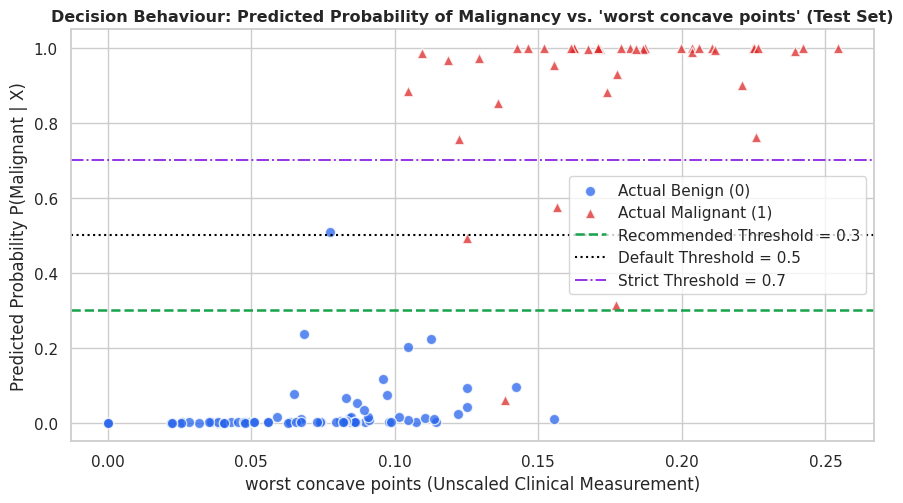

In [6]:
# Step 9: Visualise Predicted Probability vs. Strongest Feature ('worst concave points')
feat_name = 'worst concave points'

plt.figure(figsize=(9, 5.2))
benign_mask = (y_test == 0)
malign_mask = (y_test == 1)

plt.scatter(X_test.loc[benign_mask, feat_name], y_test_prob[benign_mask],
            color='#2563eb', alpha=0.75, s=55, edgecolors='white', label='Actual Benign (0)')
plt.scatter(X_test.loc[malign_mask, feat_name], y_test_prob[malign_mask],
            color='#dc2626', alpha=0.75, s=55, marker='^', edgecolors='white', label='Actual Malignant (1)')

# Show the 3 evaluated decision thresholds
plt.axhline(0.3, color='#16a34a', linestyle='--', linewidth=1.8, label='Recommended Threshold = 0.3')
plt.axhline(0.5, color='black', linestyle=':', linewidth=1.5, label='Default Threshold = 0.5')
plt.axhline(0.7, color='#9333ea', linestyle='-.', linewidth=1.4, label='Strict Threshold = 0.7')

plt.title(f"Decision Behaviour: Predicted Probability of Malignancy vs. '{feat_name}' (Test Set)", fontsize=11.5, fontweight='bold')
plt.xlabel(f"{feat_name} (Unscaled Clinical Measurement)")
plt.ylabel("Predicted Probability P(Malignant | X)")
plt.ylim(-0.05, 1.05)
plt.legend(loc='center right', frameon=True)
plt.tight_layout()
plt.show()

In [7]:
# Step 10: Construct a realistic borderline biopsy profile (60th percentile of training data — strictly in-range)
new_biopsy = X_train.quantile(0.60).to_frame().T

# Verify all 30 features lie strictly inside the training min-max bounds
in_range_count = sum(
    (X_train[col].min() <= new_biopsy[col].iloc[0] <= X_train[col].max())
    for col in X.columns
)
print(f"Range check: {in_range_count}/{len(X.columns)} features strictly within training bounds (no extrapolation).")

# Apply the EXACT same preprocessing (StandardScaler fitted on X_train only)
new_biopsy_sc = scaler.transform(new_biopsy)

# Obtain predicted probability and class at both 0.5 (default) and 0.3 (recommended)
new_prob = clf.predict_proba(new_biopsy_sc)[0, 1]
pred_default = int(new_prob >= 0.5)
pred_recommended = int(new_prob >= 0.3)

print("\n=== Key Features of New Biopsy Sample ===")
display(new_biopsy[['mean radius', 'mean texture', 'mean concave points', 'worst texture', 'worst concave points', 'worst symmetry']].round(4))

print(f"Predicted Probability of Malignancy : {new_prob:.4f} ({new_prob*100:.2f}%)")
print(f"Predicted Class at Default (0.5)    : {pred_default} ({'Malignant' if pred_default == 1 else 'Benign'})")
print(f"Predicted Class at Recommended (0.3): {pred_recommended} ({'Malignant — Flag for Urgent Clinical Review' if pred_recommended == 1 else 'Benign'})")

Range check: 30/30 features strictly within training bounds (no extrapolation).

=== Key Features of New Biopsy Sample ===


,mean radius,mean texture,mean concave points,worst texture,worst concave points,worst symmetry
0.6,14.194,20.194,0.0476,26.962,0.1221,0.2964


Predicted Probability of Malignancy : 0.4170 (41.70%)
Predicted Class at Default (0.5)    : 0 (Benign)
Predicted Class at Recommended (0.3): 1 (Malignant — Flag for Urgent Clinical Review)
